In [10]:
import pandas as pd
import numpy as np
import requests
from urllib.parse import urlparse

# 1. Load the FULL PhiUSIIL Dataset
data_path = "../data/PhiUSIIL_Phishing_URL_Dataset.csv"
df_full = pd.read_csv(data_path)

print("--- PHASE 1: DATA INGESTION ---")
print(f"Total Rows Loaded: {df_full.shape[0]:,} (Full Dataset)")
print(f"Total Columns: {df_full.shape[1]}")
display(df_full.head(3))

--- PHASE 1: DATA INGESTION ---
Total Rows Loaded: 235,795 (Full Dataset)
Total Columns: 56


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1


In [11]:
# Known URL shortening domains
SHORTENER_DOMAINS = {
    'bit.ly', 'tinyurl.com', 't.co', 'goo.gl', 'ow.ly', 
    'is.gd', 'buff.ly', 'cutt.ly', 'rb.gy', 'shorturl.at'
}

def resolve_short_url(url, timeout=5):
    """
    Phase 1 Module: Unrolls shortened URLs via HTTP HEAD/GET redirect headers
    and extracts the true destination URL, root domain, and redirect hop count.
    """
    try:
        parsed_initial = urlparse(url)
        initial_domain = parsed_initial.netloc.lower().replace("www.", "")
        is_shortened = initial_domain in SHORTENER_DOMAINS
        
        # Trace HTTP redirects without downloading heavy page content
        response = requests.head(url, allow_redirects=True, timeout=timeout)
        final_url = response.url
        redirect_hops = len(response.history)
        final_domain = urlparse(final_url).netloc.lower().replace("www.", "")
        
        return {
            "Initial_URL": url,
            "Is_Shortener_Service": is_shortened,
            "Resolved_Final_URL": final_url,
            "Extracted_Root_Domain": final_domain,
            "NoOfURLRedirect": redirect_hops
        }
    except Exception as e:
        return {
            "Initial_URL": url,
            "Error": str(e),
            "Resolved_Final_URL": url,
            "NoOfURLRedirect": 0
        }

# Quick verification test (Safe offline/online demo for your guide)
print("Short-URL Redirect Resolution Module initialized successfully.")

Short-URL Redirect Resolution Module initialized successfully.


In [12]:
import pandas as pd
import tldextract

# 1. Invert label so Phishing = 1 (Positive Class) and Legitimate = 0
# In raw PhiUSIIL: 0 = Phishing, 1 = Legitimate
df_diag = df_full.copy()
df_diag['y_phish'] = (df_diag['label'] == 0).astype(int)

# 2. Extract both Hostname (raw 'Domain' column) and True Root Domain (eTLD+1)
df_diag['clean_host'] = (
    df_diag['Domain'].astype(str).str.lower().str.strip().str.replace(r'^www\.', '', regex=True)
)

# Extract eTLD+1 (e.g., 'sub.example.co.uk' -> 'example.co.uk')
def get_registered_domain(url_or_domain):
    ext = tldextract.extract(str(url_or_domain))
    if ext.domain and ext.suffix:
        return f"{ext.domain}.{ext.suffix}".lower()
    return str(url_or_domain).lower()

print("Extracting true root domains (eTLD+1)... (takes ~10-15 seconds on 235k rows)")
df_diag['root_domain'] = df_diag['clean_host'].apply(get_registered_domain)

# ==========================================
# REPORT 1: TRUE CLASS COUNTS (Phishing = 1)
# ==========================================
total_rows = len(df_diag)
phish_count = (df_diag['y_phish'] == 1).sum()
legit_count = (df_diag['y_phish'] == 0).sum()

print("\n=== 1. TRUE CLASS DISTRIBUTION (FULL DATASET) ===")
print(f"Total Rows          : {total_rows:,}")
print(f"Phishing (y = 1)    : {phish_count:,} ({phish_count/total_rows*100:.2f}%)")
print(f"Legitimate (y = 0)  : {legit_count:,} ({legit_count/total_rows*100:.2f}%)")

# ==========================================
# REPORT 2 & 3: OVERLAP ANALYSIS FUNCTION
# ==========================================
def analyze_domain_overlap(df, col_name, label_title):
    print(f"\n=== {label_title} (`{col_name}`) ===")
    n_total = len(df)
    n_unique = df[col_name].nunique()
    
    # Count how many times each domain appears
    counts = df[col_name].value_counts()
    repeated_domains = set(counts[counts > 1].index)
    
    # Flag rows that share a domain with at least one other row
    df['is_shared'] = df[col_name].isin(repeated_domains)
    shared_rows = df['is_shared'].sum()
    
    print(f"Unique Domains               : {n_unique:,} (out of {n_total:,} rows)")
    print(f"Domains appearing >1 time    : {len(repeated_domains):,}")
    print(f"Rows sharing a domain        : {shared_rows:,} / {n_total:,} ({shared_rows/n_total*100:.2f}%)")
    
    # Breakdown by Class
    print("\n--- Breakdown by Class ---")
    for cls_val, cls_name in [(1, "Phishing (y=1)"), (0, "Legitimate (y=0)")]:
        sub = df[df['y_phish'] == cls_val]
        n_cls = len(sub)
        n_cls_unique = sub[col_name].nunique()
        
        # Shared with ANY row in the dataset
        shared_any = sub['is_shared'].sum()
        
        # Shared within the SAME class
        cls_counts = sub[col_name].value_counts()
        cls_repeated = set(cls_counts[cls_counts > 1].index)
        shared_same_cls = sub[col_name].isin(cls_repeated).sum()
        
        print(f"{cls_name}:")
        print(f"  Total Rows                 : {n_cls:,}")
        print(f"  Unique Domains             : {n_cls_unique:,}")
        print(f"  Rows sharing domain (any)  : {shared_any:,} ({shared_any/n_cls*100:.2f}%)")
        print(f"  Rows sharing domain (class): {shared_same_cls:,} ({shared_same_cls/n_cls*100:.2f}%)")

    # Check cross-class domains (domains that have BOTH phishing and legitimate URLs)
    phish_domains = set(df[df['y_phish'] == 1][col_name])
    legit_domains = set(df[df['y_phish'] == 0][col_name])
    both_classes = phish_domains.intersection(legit_domains)
    rows_in_both = df[col_name].isin(both_classes).sum()
    print(f"\nDomains present in BOTH Phishing & Legit : {len(both_classes):,} domains ({rows_in_both:,} rows, {rows_in_both/n_total*100:.2f}%)")

# Run analysis on both raw 'Domain' (hostname) and true 'root_domain' (eTLD+1)
analyze_domain_overlap(df_diag, 'clean_host', "2A. RAW HOSTNAME OVERLAP")
analyze_domain_overlap(df_diag, 'root_domain', "2B. TRUE ROOT DOMAIN (eTLD+1) OVERLAP")

Extracting true root domains (eTLD+1)... (takes ~10-15 seconds on 235k rows)

=== 1. TRUE CLASS DISTRIBUTION (FULL DATASET) ===
Total Rows          : 235,795
Phishing (y = 1)    : 100,945 (42.81%)
Legitimate (y = 0)  : 134,850 (57.19%)

=== 2A. RAW HOSTNAME OVERLAP (`clean_host`) ===
Unique Domains               : 219,103 (out of 235,795 rows)
Domains appearing >1 time    : 5,871
Rows sharing a domain        : 22,563 / 235,795 (9.57%)

--- Breakdown by Class ---
Phishing (y=1):
  Total Rows                 : 100,945
  Unique Domains             : 84,311
  Rows sharing domain (any)  : 22,505 (22.29%)
  Rows sharing domain (class): 22,453 (22.24%)
Legitimate (y=0):
  Total Rows                 : 134,850
  Unique Domains             : 134,850
  Rows sharing domain (any)  : 58 (0.04%)
  Rows sharing domain (class): 0 (0.00%)

Domains present in BOTH Phishing & Legit : 58 domains (159 rows, 0.07%)

=== 2B. TRUE ROOT DOMAIN (eTLD+1) OVERLAP (`root_domain`) ===
Unique Domains               : 

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

# 1. Print the missing Phishing Root-Domain (eTLD+1) overlap numbers (Point #2)
sub_phish = df_diag[df_diag['y_phish'] == 1]
p_root_counts = sub_phish['root_domain'].value_counts()
p_repeated_roots = set(p_root_counts[p_root_counts > 1].index)
p_shared_in_phish = sub_phish['root_domain'].isin(p_repeated_roots).sum()

all_root_counts = df_diag['root_domain'].value_counts()
all_repeated_roots = set(all_root_counts[all_root_counts > 1].index)
p_shared_any = sub_phish['root_domain'].isin(all_repeated_roots).sum()

print("=== 1. MISSING PHISHING ROOT-DOMAIN (eTLD+1) STATS ===")
print(f"Total Phishing Rows (y=1)                 : {len(sub_phish):,}")
print(f"Unique Phishing Root Domains (eTLD+1)     : {sub_phish['root_domain'].nunique():,}")
print(f"Phishing rows sharing root domain (any)   : {p_shared_any:,} ({p_shared_any/len(sub_phish)*100:.2f}%)")
print(f"Phishing rows sharing root domain (class) : {p_shared_in_phish:,} ({p_shared_in_phish/len(sub_phish)*100:.2f}%)")

print("\n--- Top 15 Most Repeated Phishing Root Domains (eTLD+1) ---")
print(p_root_counts.head(15).to_string())

# 2. Direct Train-to-Test Leakage & Fold Class-Balance Check (Points #3 & #5)
y_full = df_diag['y_phish'].values
groups_full = df_diag['root_domain'].values
X_dummy = np.zeros((len(df_diag), 1))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

=== 1. MISSING PHISHING ROOT-DOMAIN (eTLD+1) STATS ===
Total Phishing Rows (y=1)                 : 100,945
Unique Phishing Root Domains (eTLD+1)     : 43,512
Phishing rows sharing root domain (any)   : 62,828 (62.24%)
Phishing rows sharing root domain (class) : 62,741 (62.15%)

--- Top 15 Most Repeated Phishing Root Domains (eTLD+1) ---
root_domain
web.app             5754
firebaseapp.com     5594
repl.co             3754
weeblysite.com      3097
ipfs.io             1559
workers.dev         1438
square.site         1199
dweb.link            975
xsph.ru              928
pantheonsite.io      900
google.com           782
godaddysites.com     781
duckdns.org          642
webwave.dev          567
weebly.com           555


In [14]:

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

y_full = df_diag['y_phish'].values
groups_full = pd.factorize(df_diag['root_domain'])[0]   # integer IDs, done once
X_dummy = np.zeros((len(df_diag), 1))

def audit(splitter, name, use_groups):
    rows = []
    split_iter = splitter.split(X_dummy, y_full, groups_full) if use_groups else splitter.split(X_dummy, y_full)
    n_groups = groups_full.max() + 1
    for fold, (tr, te) in enumerate(split_iter, 1):
        seen = np.zeros(n_groups, dtype=bool)
        seen[groups_full[tr]] = True            # mark groups present in train
        leaked = seen[groups_full[te]]          # fast lookup
        te_y = y_full[te]
        rows.append({
            "Fold": fold, "Test Size": len(te),
            "Phish Rate (%)": round(te_y.mean()*100, 2),
            "Overall Leaked (%)": round(leaked.mean()*100, 2),
            "Phish Test Leaked (%)": round(leaked[te_y == 1].mean()*100, 2),
            "Legit Test Leaked (%)": round(leaked[te_y == 0].mean()*100, 2),
        })
    print(f"\n=== {name} ===")
    print(pd.DataFrame(rows).to_string(index=False))

audit(StratifiedKFold(5, shuffle=True, random_state=42), "RANDOM (StratifiedKFold)", False)
audit(StratifiedGroupKFold(5, shuffle=True, random_state=42), "GROUPED (StratifiedGroupKFold)", True)


=== RANDOM (StratifiedKFold) ===
 Fold  Test Size  Phish Rate (%)  Overall Leaked (%)  Phish Test Leaked (%)  Legit Test Leaked (%)
    1      47159           42.81               27.74                  61.47                   2.48
    2      47159           42.81               27.48                  60.77                   2.56
    3      47159           42.81               27.35                  60.71                   2.38
    4      47159           42.81               27.57                  60.92                   2.60
    5      47159           42.81               27.36                  60.84                   2.30

=== GROUPED (StratifiedGroupKFold) ===
 Fold  Test Size  Phish Rate (%)  Overall Leaked (%)  Phish Test Leaked (%)  Legit Test Leaked (%)
    1      47159           42.81                 0.0                    0.0                    0.0
    2      47159           42.81                 0.0                    0.0                    0.0
    3      47159           42.81   

In [15]:

print("--- PHASE 2: DUAL-TRACK SPLITTING SETUP ---")

# 1. Define STRICTLY Pure Lexical Features (No live-request/redirect features)
pure_lexical_features = [
    'URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain',
    'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio',
    'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL',
    'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL',
    'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL'
]

X = df_diag[[col for col in pure_lexical_features if col in df_diag.columns]]
y = df_diag['y_phish'].values
groups = df_diag['root_domain'].values

# Verification to prevent silent dropping
print(f"Features strictly used ({len(X.columns)}):", X.columns.tolist())
print(f"Shape of Feature Matrix (X): {X.shape}")
print(f"Shape of Target Vector (y) : {y.shape}")

# 2. Define the exact Splitters for Track 2A and Track 2B
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("\nTrack 2A Splitter Ready: StratifiedKFold (5 Folds, Random, baseline)")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
print("Track 2B Splitter Ready: StratifiedGroupKFold (5 Folds, Grouped by root_domain, leakage-free)")

--- PHASE 2: DUAL-TRACK SPLITTING SETUP ---
Features strictly used (17): ['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL']
Shape of Feature Matrix (X): (235795, 17)
Shape of Target Vector (y) : (235795,)

Track 2A Splitter Ready: StratifiedKFold (5 Folds, Random, baseline)
Track 2B Splitter Ready: StratifiedGroupKFold (5 Folds, Grouped by root_domain, leakage-free)


In [16]:


from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)

print("--- PHASE 3 & 4: MODEL TRAINING & MASTER AUDIT TABLE ---")

# Change 1: integer group IDs (faster grouping, same result)
groups = pd.factorize(df_diag['root_domain'])[0]

# Splitters defined here so this cell is self-contained
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

print(f"X shape: {X.shape}, y shape: {y.shape}, groups: {len(np.unique(groups)):,} unique")

def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Linear SVM": CalibratedClassifierCV(LinearSVC(dual=False, random_state=42, max_iter=2000), cv=2),
        "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
        "XGBoost": XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.2,
                                 n_jobs=-1, random_state=42, eval_metric='logloss')
    }

def evaluate_cv(cv_splitter, is_grouped=False):
    models = get_models()
    results = {name: [] for name in models}
    splits = cv_splitter.split(X, y, groups) if is_grouped else cv_splitter.split(X, y)

    for fold, (train_idx, test_idx) in enumerate(splits, 1):
        print(f"  fold {fold}/5")
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]

        scaler = StandardScaler()                      # fitted inside the fold
        X_tr_sc = scaler.fit_transform(X_tr)
        X_te_sc = scaler.transform(X_te)

        for name, model in models.items():
            use_sc = name in ["Logistic Regression", "Linear SVM"]
            tr_data = X_tr_sc if use_sc else X_tr
            te_data = X_te_sc if use_sc else X_te

            model.fit(tr_data, y_tr)
            preds = model.predict(te_data)
            probs = model.predict_proba(te_data)[:, 1]

            results[name].append({
                "Acc": accuracy_score(y_te, preds) * 100,
                "Prec": precision_score(y_te, preds) * 100,
                "Rec": recall_score(y_te, preds) * 100,
                "F1": f1_score(y_te, preds) * 100,
                "ROC_AUC": roc_auc_score(y_te, probs) * 100,
                "PR_AUC": average_precision_score(y_te, probs) * 100
            })

    out = {}
    for name, lst in results.items():
        d = pd.DataFrame(lst)
        out[name] = {**d.mean().to_dict(),
                     **{f"{k}_std": v for k, v in d.std().to_dict().items()}}
    return out

print("Running Track 2A (Random Split)...")
results_skf = evaluate_cv(skf, is_grouped=False)
print("Running Track 2B (Domain Grouped Split)...")
results_sgkf = evaluate_cv(sgkf, is_grouped=True)

def fmt(m, k):
    return f"{m[k]:.2f} ± {m[k + '_std']:.2f}"

rows = []
for name in get_models():
    A, B = results_skf[name], results_sgkf[name]
    rows.append({
        "Algorithm": name,
        "Acc A": fmt(A, "Acc"), "Acc B": fmt(B, "Acc"),
        "Prec A": fmt(A, "Prec"), "Prec B": fmt(B, "Prec"),
        "Rec A": fmt(A, "Rec"), "Rec B": fmt(B, "Rec"),
        "F1 A": fmt(A, "F1"), "F1 B": fmt(B, "F1"),
        "PR-AUC A": fmt(A, "PR_AUC"), "PR-AUC B": fmt(B, "PR_AUC"),
    })
master_table = pd.DataFrame(rows)

# Change 2: separate compact gap table (A minus B), including Precision gap
gap_table = pd.DataFrame([{
    "Algorithm": name,
    "Acc Δ": round(results_skf[name]["Acc"] - results_sgkf[name]["Acc"], 2),
    "Prec Δ": round(results_skf[name]["Prec"] - results_sgkf[name]["Prec"], 2),
    "Rec Δ": round(results_skf[name]["Rec"] - results_sgkf[name]["Rec"], 2),
    "F1 Δ": round(results_skf[name]["F1"] - results_sgkf[name]["F1"], 2),
    "ROC-AUC Δ": round(results_skf[name]["ROC_AUC"] - results_sgkf[name]["ROC_AUC"], 2),
    "PR-AUC Δ": round(results_skf[name]["PR_AUC"] - results_sgkf[name]["PR_AUC"], 2),
} for name in get_models()])

print("\n=== MASTER AUDIT TABLE (mean ± std over 5 folds) ===")
display(master_table)
print("\n=== GENERALIZATION GAP (Track A minus Track B) ===")
display(gap_table)

--- PHASE 3 & 4: MODEL TRAINING & MASTER AUDIT TABLE ---
X shape: (235795, 17), y shape: (235795,), groups: 175,509 unique
Running Track 2A (Random Split)...
  fold 1/5
  fold 2/5
  fold 3/5
  fold 4/5
  fold 5/5
Running Track 2B (Domain Grouped Split)...
  fold 1/5
  fold 2/5
  fold 3/5
  fold 4/5
  fold 5/5

=== MASTER AUDIT TABLE (mean ± std over 5 folds) ===


,Algorithm,Acc A,Acc B,Prec A,Prec B,Rec A,Rec B,F1 A,F1 B,PR-AUC A,PR-AUC B
0,Logistic Regression,98.38 ± 0.24,98.37 ± 0.29,99.86 ± 0.03,99.85 ± 0.06,96.36 ± 0.53,96.34 ± 0.71,98.07 ± 0.29,98.06 ± 0.35,99.73 ± 0.03,99.73 ± 0.08
1,Decision Tree,99.67 ± 0.03,99.61 ± 0.07,99.81 ± 0.05,99.76 ± 0.10,99.42 ± 0.05,99.33 ± 0.07,99.62 ± 0.03,99.55 ± 0.08,99.59 ± 0.06,99.49 ± 0.13
2,Linear SVM,99.67 ± 0.02,99.68 ± 0.04,99.99 ± 0.01,99.99 ± 0.01,99.24 ± 0.06,99.27 ± 0.09,99.62 ± 0.03,99.63 ± 0.05,99.88 ± 0.01,99.88 ± 0.03
3,Random Forest,99.68 ± 0.03,99.65 ± 0.06,99.78 ± 0.07,99.74 ± 0.11,99.48 ± 0.03,99.44 ± 0.06,99.63 ± 0.03,99.59 ± 0.07,99.87 ± 0.01,99.87 ± 0.02
4,XGBoost,99.74 ± 0.01,99.71 ± 0.05,99.89 ± 0.03,99.84 ± 0.09,99.50 ± 0.03,99.47 ± 0.04,99.69 ± 0.01,99.66 ± 0.05,99.89 ± 0.01,99.89 ± 0.02



=== GENERALIZATION GAP (Track A minus Track B) ===


,Algorithm,Acc Δ,Prec Δ,Rec Δ,F1 Δ,ROC-AUC Δ,PR-AUC Δ
0,Logistic Regression,0.01,0.01,0.01,0.01,0.01,0.01
1,Decision Tree,0.06,0.05,0.09,0.07,0.09,0.10
2,Linear SVM,-0.01,0.00,-0.02,-0.01,-0.00,-0.00
3,Random Forest,0.03,0.04,0.03,0.04,-0.00,0.00
4,XGBoost,0.03,0.05,0.03,0.04,-0.00,-0.00


In [17]:
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

urls = df_diag['URL'].astype(str).values
y = df_diag['y_phish'].values

# Part 1: what does the model look at?
vec = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), max_features=300_000,
                      lowercase=True, sublinear_tf=True)
Xall = vec.fit_transform(urls)
clf = LinearSVC(C=1.0, max_iter=2000).fit(Xall, y)
names = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])
print("LEGIT-indicating pieces:", list(names[order[:25]]))
print("PHISH-indicating pieces:", list(names[order[-25:]]))

# Part 2: simple prefix check
s = pd.Series(urls)
for pat in ["https://www.", "http://", "https://"]:
    m = s.str.startswith(pat)
    print(f"{pat:14s} -> phishing rate {y[m].mean()*100:.1f}%  (rows: {m.sum():,})")

LEGIT-indicating pieces: ['s://w', '/www.', 'www.', 'ww.', '//www', '/www', 'www', '//ww', '://ww', '/ww', '://w', '//w', 'ps://', 's://', 'tps:/', 's:/', 'ps:/', 'tps:', 'ttps:', 'ps:', 'ttps', 'https', 'tps', '.go', 'w.top']
PHISH-indicating pieces: ['.top/', 'php', '.php', '.cn/', 'cn/', 'de/', '.to', 'op/', '365', 'et/', 'net/', '.net/', '.top', 'http:', 'p:/', 'ttp:', 'ttp:/', 'tp:/', 'tp:', 'tp://', 'p://', 'p://w', 'om/', 'com/', '.com/']
https://www.   -> phishing rate 1.8%  (rows: 137,299)
http://        -> phishing rate 100.0%  (rows: 51,749)
https://       -> phishing rate 26.7%  (rows: 184,046)


In [18]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

urls = df_diag['URL'].astype(str)
y = df_diag['y_phish']                      # 1 = phishing, 0 = legitimate

# Rule: if the URL starts with "https://www." call it legitimate, otherwise phishing
pred = (~urls.str.startswith("https://www.")).astype(int)

print("Accuracy :", round(accuracy_score(y, pred) * 100, 2))
print("Precision:", round(precision_score(y, pred) * 100, 2))
print("Recall   :", round(recall_score(y, pred) * 100, 2))
print("F1       :", round(f1_score(y, pred) * 100, 2))

Accuracy : 98.96
Precision: 100.0
Recall   : 97.57
F1       : 98.77


C:\Users\Yuvraj\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Track A: Fold-1 XGBoost F1 = 99.69


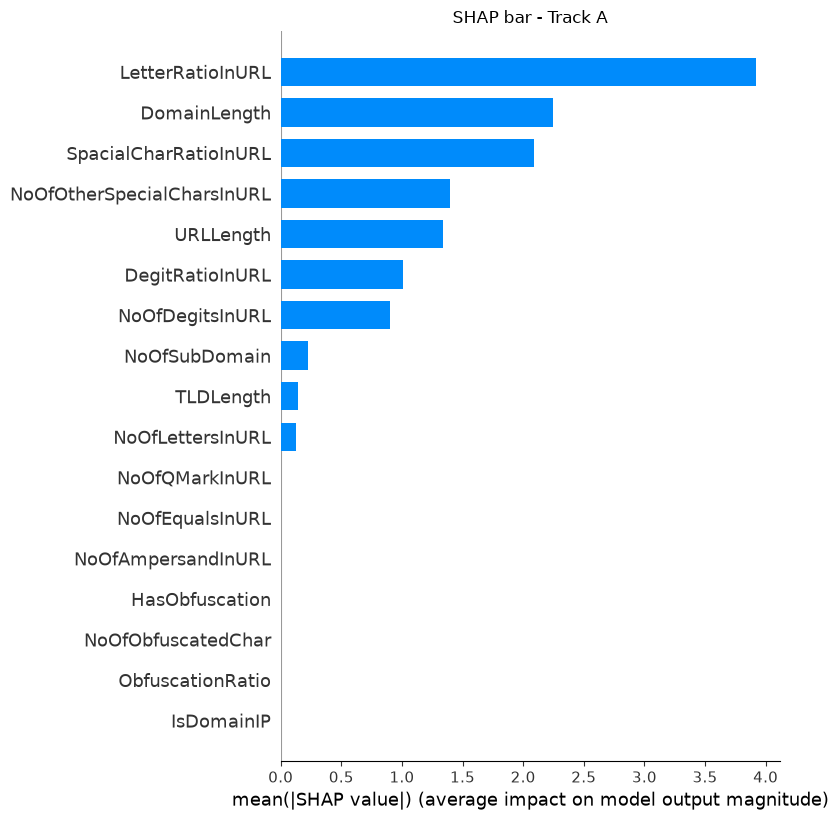

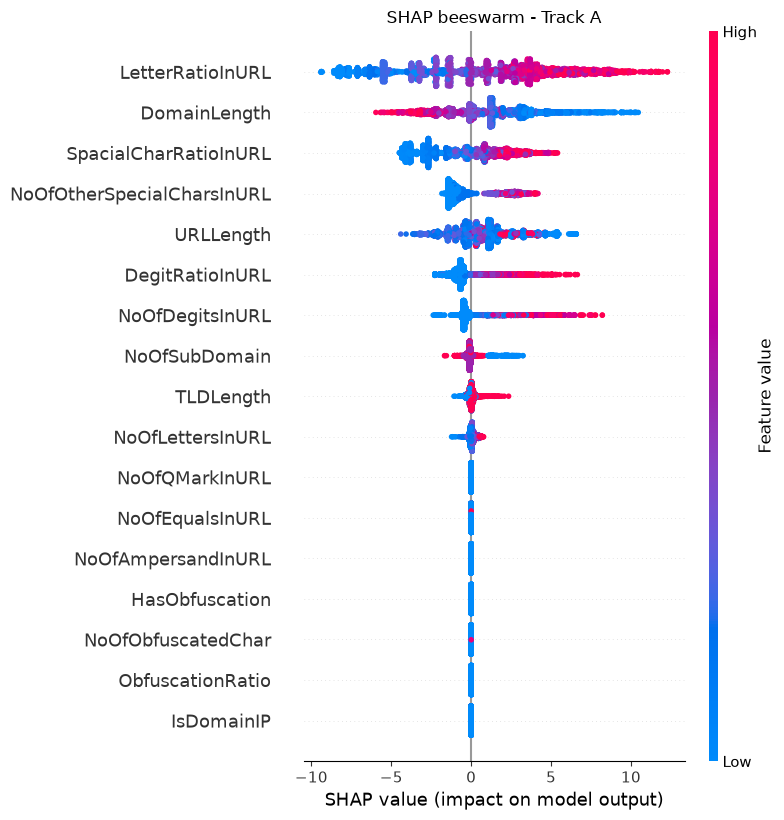

Track B: Fold-1 XGBoost F1 = 99.69


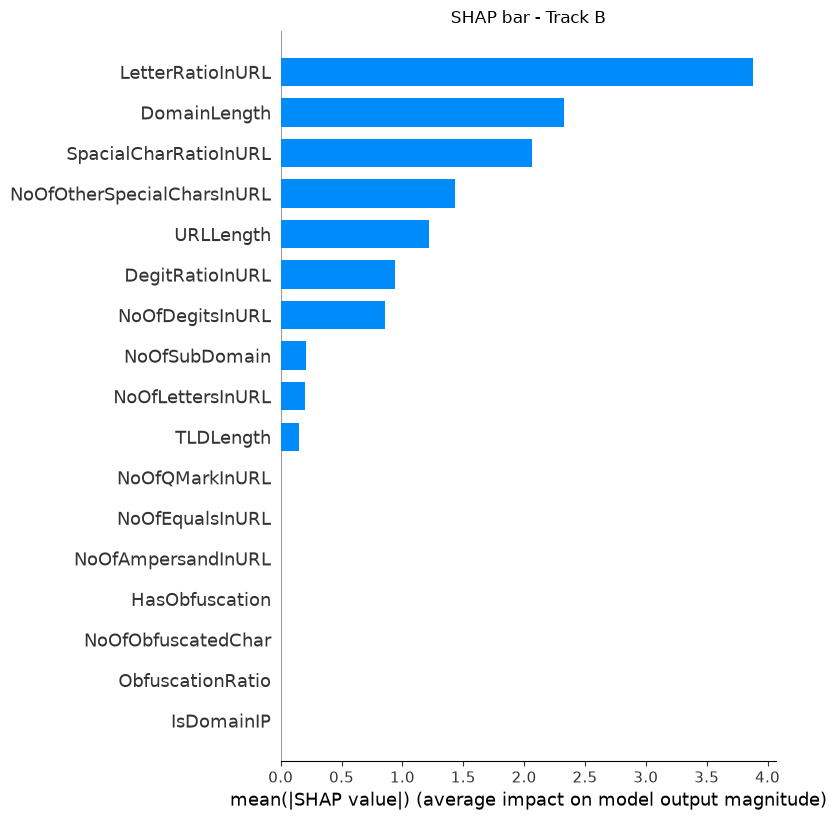

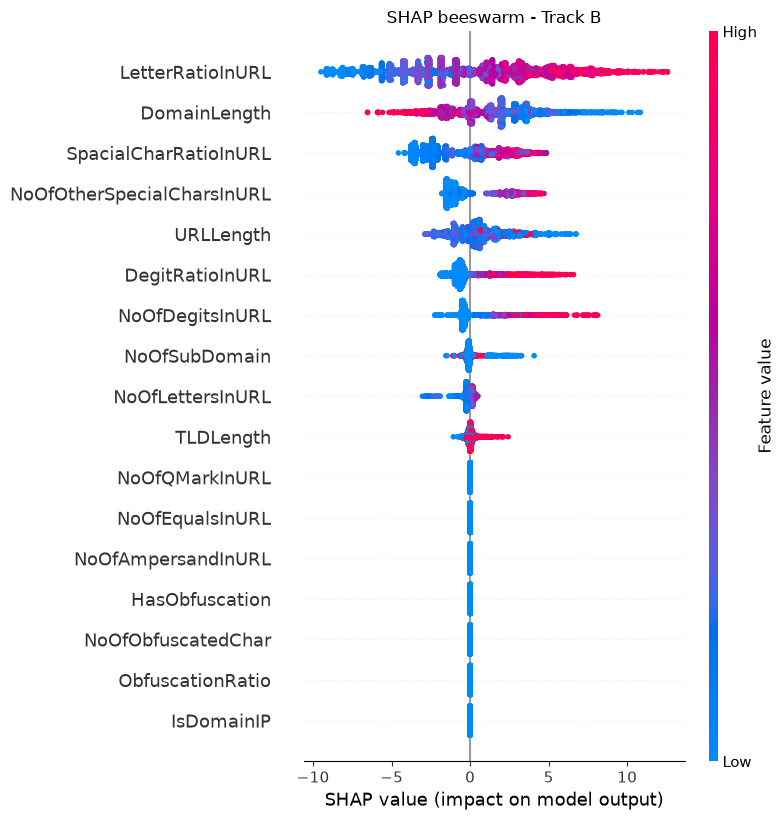

                   Feature  |SHAP| A    Rel% A  |SHAP| B    Rel% B
          LetterRatioInURL    3.9224 29.290001    3.8776 29.209999
              DomainLength    2.2496 16.799999    2.3301 17.549999
     SpacialCharRatioInURL    2.0910 15.610000    2.0648 15.560000
NoOfOtherSpecialCharsInURL    1.3974 10.430000    1.4341 10.800000
                 URLLength    1.3402 10.010000    1.2174  9.170000
           DegitRatioInURL    1.0049  7.500000    0.9402  7.080000
           NoOfDegitsInURL    0.9028  6.740000    0.8532  6.430000
             NoOfSubDomain    0.2228  1.660000    0.2108  1.590000
          NoOfLettersInURL    0.1225  0.910000    0.1962  1.480000
                 TLDLength    0.1398  1.040000    0.1488  1.120000
        NoOfObfuscatedChar    0.0000  0.000000    0.0000  0.000000
            HasObfuscation    0.0000  0.000000    0.0000  0.000000
                IsDomainIP    0.0000  0.000000    0.0000  0.000000
          ObfuscationRatio    0.0000  0.000000    0.0000  0.00

In [19]:
import shap, numpy as np, pandas as pd, matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import f1_score

def shap_fold1(splitter, grouped, tag):
    splits = splitter.split(X, y, groups) if grouped else splitter.split(X, y)
    tr, te = next(iter(splits))                       # Fold 1 only
    model = XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.2,
                          n_jobs=-1, random_state=42, eval_metric='logloss')
    model.fit(X.iloc[tr], y[tr])
    f1 = f1_score(y[te], model.predict(X.iloc[te])) * 100
    idx = np.random.RandomState(42).choice(len(te), size=min(5000, len(te)), replace=False)
    Xs = X.iloc[te].iloc[idx]                         # 5,000 random test rows
    sv = shap.TreeExplainer(model).shap_values(Xs)
    imp = np.abs(sv).mean(axis=0)
    df = pd.DataFrame({"Feature": X.columns,
                       f"|SHAP| {tag}": imp.round(4),
                       f"Rel% {tag}": (imp / imp.sum() * 100).round(2)})
    print(f"Track {tag}: Fold-1 XGBoost F1 = {f1:.2f}")
    for kind, name in [("bar", "bar"), (None, "beeswarm")]:
        plt.figure(figsize=(9, 6))
        shap.summary_plot(sv, Xs, plot_type=kind, show=False)
        plt.title(f"SHAP {name} - Track {tag}")
        plt.tight_layout()
        plt.savefig(f"shap_{name}_track{tag}.png", dpi=300)
        plt.show()
    return df

dfA = shap_fold1(skf, False, "A")      # random split
dfB = shap_fold1(sgkf, True, "B")      # domain-grouped split

table = dfA.merge(dfB, on="Feature").sort_values("|SHAP| B", ascending=False)
print(table.to_string(index=False))
table.to_csv("shap_comparison.csv", index=False)

In [20]:
import re, numpy as np, pandas as pd

print("--- ABLATION: prefix-stripped lexical features (with control) ---")

def strip_prefix(u):
    u = re.sub(r'^https?://', '', str(u).strip(), flags=re.I)
    return re.sub(r'^www\.', '', u, flags=re.I)

def feats(u, strip=True):
    u = str(u).strip()
    core = strip_prefix(u)                       # used only to find the hostname
    s = core if strip else u                     # strip=False keeps http(s):// and www.
    host = core.split('/')[0].split('?')[0].split(':')[0]
    L = len(s)
    letters = sum(c.isalpha() for c in s); digits = sum(c.isdigit() for c in s)
    other = L - letters - digits
    parts = host.split('.')
    return dict(URLLength=L, DomainLength=len(host),
                NoOfSubDomain=max(len(parts) - 2, 0), TLDLength=len(parts[-1]),
                NoOfLetters=letters, LetterRatio=letters/max(L, 1),
                NoOfDigits=digits, DigitRatio=digits/max(L, 1),
                NoOfSpecial=other, SpecialRatio=other/max(L, 1),
                NoOfEquals=s.count('='), NoOfQMark=s.count('?'), NoOfAmp=s.count('&'))

variants = {"13 feats, prefix KEPT (control)": False,
            "13 feats, prefix STRIPPED": True}
runs = {}
X_orig = X                                       # remember the original features
try:
    for vname, strip in variants.items():
        print(f"\nBuilding features: {vname}")
        X = pd.DataFrame([feats(u, strip) for u in df_diag['URL']]).astype('float32')
        print("  Track A (random)...");  rA = evaluate_cv(skf,  is_grouped=False)
        print("  Track B (grouped)..."); rB = evaluate_cv(sgkf, is_grouped=True)
        runs[vname] = (rA, rB)
finally:
    X = X_orig                                   # always restore, even after an error

f = lambda m, k: f"{m[k]:.2f} ± {m[k + '_std']:.2f}"
rows = []
for vname, (rA, rB) in runs.items():
    for name in get_models():
        A, B = rA[name], rB[name]
        rows.append({"Features": vname, "Algorithm": name,
                     "Prec A": f(A, "Prec"), "Prec B": f(B, "Prec"),
                     "Rec A": f(A, "Rec"),   "Rec B": f(B, "Rec"),
                     "F1 A": f(A, "F1"),     "F1 B": f(B, "F1"),
                     "F1 Gap": round(A["F1"] - B["F1"], 2),
                     "PR-AUC A": f(A, "PR_AUC"), "PR-AUC B": f(B, "PR_AUC"),
                     "PR-AUC Gap": round(A["PR_AUC"] - B["PR_AUC"], 2)})
ablation_table = pd.DataFrame(rows)
display(ablation_table)
ablation_table.to_csv("ablation_table.csv", index=False)

--- ABLATION: prefix-stripped lexical features (with control) ---

Building features: 13 feats, prefix KEPT (control)
  Track A (random)...
  fold 1/5
  fold 2/5
  fold 3/5
  fold 4/5
  fold 5/5
  Track B (grouped)...
  fold 1/5
  fold 2/5
  fold 3/5
  fold 4/5
  fold 5/5

Building features: 13 feats, prefix STRIPPED
  Track A (random)...
  fold 1/5
  fold 2/5
  fold 3/5
  fold 4/5
  fold 5/5
  Track B (grouped)...
  fold 1/5
  fold 2/5
  fold 3/5
  fold 4/5
  fold 5/5


,Features,Algorithm,Prec A,Prec B,Rec A,Rec B,F1 A,F1 B,F1 Gap,PR-AUC A,PR-AUC B,PR-AUC Gap
0,"13 feats, prefix KEPT (control)",Logistic Regression,88.92 ± 0.47,88.77 ± 0.47,68.12 ± 0.36,68.13 ± 1.41,77.14 ± 0.35,77.09 ± 0.98,0.05,88.13 ± 0.08,88.07 ± 0.45,0.06
1,"13 feats, prefix KEPT (control)",Decision Tree,99.74 ± 0.06,99.69 ± 0.11,98.89 ± 0.13,98.48 ± 0.65,99.31 ± 0.06,99.08 ± 0.32,0.23,99.42 ± 0.08,99.12 ± 0.36,0.29
2,"13 feats, prefix KEPT (control)",Linear SVM,88.77 ± 0.35,88.63 ± 0.54,68.14 ± 0.37,68.13 ± 1.40,77.10 ± 0.28,77.03 ± 0.95,0.07,88.14 ± 0.09,88.08 ± 0.46,0.05
3,"13 feats, prefix KEPT (control)",Random Forest,99.60 ± 0.08,99.56 ± 0.11,98.96 ± 0.14,98.73 ± 0.27,99.28 ± 0.05,99.14 ± 0.14,0.13,99.81 ± 0.03,99.79 ± 0.03,0.02
4,"13 feats, prefix KEPT (control)",XGBoost,99.83 ± 0.03,99.78 ± 0.10,99.14 ± 0.11,99.12 ± 0.07,99.49 ± 0.04,99.45 ± 0.08,0.04,99.86 ± 0.02,99.85 ± 0.02,0.00
5,"13 feats, prefix STRIPPED",Logistic Regression,95.70 ± 0.29,95.67 ± 0.19,69.39 ± 0.46,69.42 ± 1.72,80.45 ± 0.30,80.45 ± 1.13,-0.00,88.93 ± 0.13,88.92 ± 0.34,0.01
6,"13 feats, prefix STRIPPED",Decision Tree,95.60 ± 0.23,95.41 ± 0.60,72.68 ± 0.20,72.25 ± 0.99,82.58 ± 0.15,82.23 ± 0.67,0.35,90.60 ± 0.17,90.27 ± 0.42,0.33
7,"13 feats, prefix STRIPPED",Linear SVM,95.75 ± 0.25,95.74 ± 0.23,68.95 ± 0.36,68.96 ± 1.47,80.17 ± 0.25,80.17 ± 0.95,0.00,89.02 ± 0.14,88.99 ± 0.35,0.02
8,"13 feats, prefix STRIPPED",Random Forest,95.31 ± 0.17,95.19 ± 0.47,72.97 ± 0.23,72.73 ± 0.83,82.66 ± 0.14,82.45 ± 0.54,0.21,90.90 ± 0.12,90.77 ± 0.34,0.13
9,"13 feats, prefix STRIPPED",XGBoost,95.40 ± 0.14,95.37 ± 0.49,72.95 ± 0.26,72.70 ± 0.86,82.68 ± 0.14,82.50 ± 0.58,0.18,91.02 ± 0.10,90.88 ± 0.38,0.14


In [21]:
import re

def feats2(u, strip):
    u = str(u).strip()
    no_scheme = re.sub(r'^https?://', '', u, flags=re.I)        # keeps www.
    core = re.sub(r'^www\.', '', no_scheme, flags=re.I)         # no scheme, no www.
    s = core if strip else u
    host = (core if strip else no_scheme).split('/')[0].split('?')[0].split(':')[0]
    L = len(s)
    letters = sum(c.isalpha() for c in s); digits = sum(c.isdigit() for c in s)
    parts = host.split('.')
    return dict(URLLength=L, DomainLength=len(host),
                NoOfSubDomain=max(len(parts) - 2, 0), TLDLength=len(parts[-1]),
                NoOfLettersInURL=letters, NoOfDegitsInURL=digits)

chk = pd.DataFrame([feats2(u, strip=False) for u in df_diag['URL']])
for col in chk.columns:
    print(col, "match with original:", round((chk[col].values == df_diag[col].values).mean() * 100, 2), "%")

URLLength match with original: 20.63 %
DomainLength match with original: 99.99 %
NoOfSubDomain match with original: 100.0 %
TLDLength match with original: 99.99 %
NoOfLettersInURL match with original: 0.0 %
NoOfDegitsInURL match with original: 99.49 %
